In [1]:
# BƯỚC 1: KHAI BÁO THƯ VIỆN VÀ TẢI DỮ LIỆU
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score
from scipy.stats import mode

# Tải bộ dữ liệu chữ số viết tay MNIST (scikit-learn load_digits)
digits = load_digits()
X = digits.data
y = digits.target

print(f"Số lượng mẫu dữ liệu: {X.shape[0]}")
print(f"Kích thước vector mỗi ảnh: {X.shape[1]} thuộc tính (ảnh 8x8 làm phẳng)")
print(f"Các lớp nhãn thực tế có sẵn: {np.unique(y)}")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Số lượng mẫu dữ liệu: 1797
Kích thước vector mỗi ảnh: 64 thuộc tính (ảnh 8x8 làm phẳng)
Các lớp nhãn thực tế có sẵn: [0 1 2 3 4 5 6 7 8 9]


In [2]:
# BƯỚC 2: GOM CỤM BẰNG THUẬT TOÁN K-MEANS
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Khởi tạo mô hình K-Means với k = 10 cụm tương ứng 10 chữ số (0 - 9)
kmeans = KMeans(n_clusters=10, init='k-means++', random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)

print("Đã hoàn tất quá trình gom cụm dữ liệu MNIST.")
print("Phân phối số lượng mẫu trong 10 cụm:")
unique, counts = np.unique(clusters, return_counts=True)
for u, c in zip(unique, counts):
    print(f" - Cụm {u}: {c} mẫu")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Đã hoàn tất quá trình gom cụm dữ liệu MNIST.
Phân phối số lượng mẫu trong 10 cụm:
 - Cụm 0: 176 mẫu
 - Cụm 1: 179 mẫu
 - Cụm 2: 89 mẫu
 - Cụm 3: 226 mẫu
 - Cụm 4: 198 mẫu
 - Cụm 5: 182 mẫu
 - Cụm 6: 181 mẫu
 - Cụm 7: 157 mẫu
 - Cụm 8: 241 mẫu
 - Cụm 9: 168 mẫu


Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


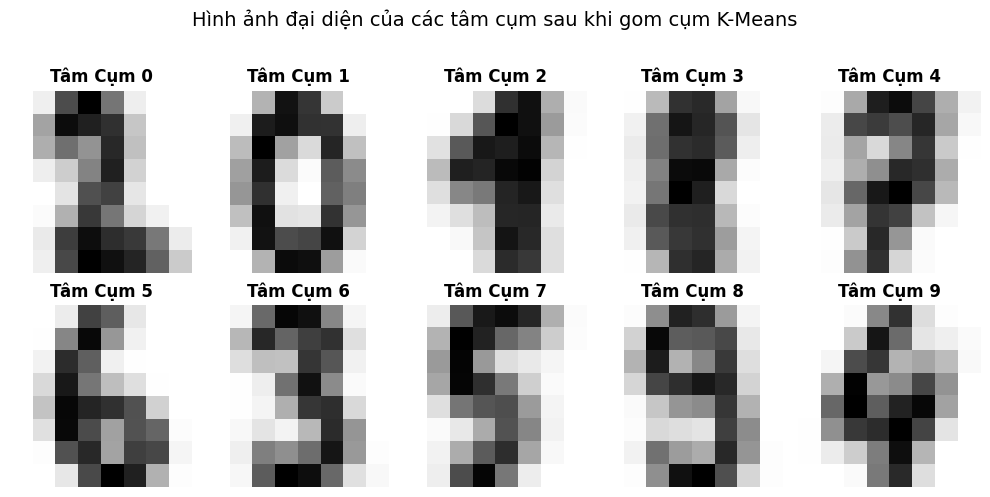

In [3]:
# BƯỚC 3: TRỰC QUAN HÓA TÂM CỤM (CENTROIDS)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)

for i, ax in enumerate(axes.flat):
    ax.imshow(centers[i], cmap=plt.cm.binary, interpolation='nearest')
    ax.set_title(f'Tâm Cụm {i}', fontsize=12, fontweight='bold')
    ax.axis('off')

plt.suptitle("Hình ảnh đại diện của các tâm cụm sau khi gom cụm K-Means", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [4]:
# BƯỚC 4: ÁNH XẠ CỤM VÀ SO SÁNH VỚI NHÃN THỰC TẾ
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Gán nhãn cho từng cụm dựa vào nhãn lớp thực tế chiếm đa số
labels_mapped = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    if np.sum(mask) > 0:
        majority_digit = mode(y[mask], keepdims=True)[0][0]
        labels_mapped[mask] = majority_digit
        print(f"Cụm {i} được ánh xạ về Chữ số: {majority_digit}")

# Đánh giá bằng Accuracy và Báo cáo phân loại
acc = accuracy_score(y, labels_mapped)
sil = silhouette_score(X, clusters)

print(f"\n=> Độ khớp (Accuracy) giữa kết quả gom cụm và nhãn có sẵn: {acc * 100:.2f}%")
print(f"=> Hệ số Dáng điệu (Silhouette Coefficient): {sil:.4f}\n")

print("--- BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE) ---")
print(classification_report(y, labels_mapped, digits=4))

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Cụm 0 được ánh xạ về Chữ số: 2
Cụm 1 được ánh xạ về Chữ số: 0
Cụm 2 được ánh xạ về Chữ số: 1
Cụm 3 được ánh xạ về Chữ số: 8
Cụm 4 được ánh xạ về Chữ số: 7
Cụm 5 được ánh xạ về Chữ số: 6
Cụm 6 được ánh xạ về Chữ số: 3
Cụm 7 được ánh xạ về Chữ số: 5
Cụm 8 được ánh xạ về Chữ số: 9
Cụm 9 được ánh xạ về Chữ số: 4

=> Độ khớp (Accuracy) giữa kết quả gom cụm và nhãn có sẵn: 79.35%
=> Hệ số Dáng điệu (Silhouette Coefficient): 0.1824

--- BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE) ---
              precision    recall  f1-score   support

           0     0.9888    0.9944    0.9916       178
           1     0.6180    0.3022    0.4059       182
           2     0.8409    0.8362    0.8385       177
           3     0.8564    0.8470    0.8516       183
           4     0.9881    0.9171    0.9513       181
           5     0.8726    0.7527    0.8083       182
           6     0.9725    0.9779    0.9752       181
          

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


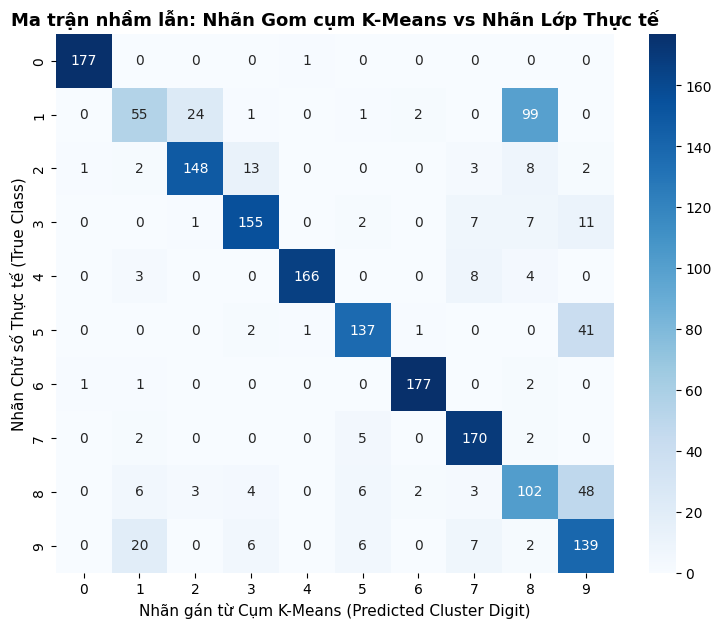

Nhận xét: Phần lớn các mẫu nằm trên đường chéo chính của ma trận nhầm lẫn, chứng minh K-Means đã gom các chữ số cùng loại về chung các cụm tương ứng rất tốt.


In [5]:
# BƯỚC 5: MA TRẬN NHẦM LẪN SO SÁNH KẾT QUẢ GOM CỤM VÀ NHÃN CÓ SẴN
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

cm = confusion_matrix(y, labels_mapped)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title("Ma trận nhầm lẫn: Nhãn Gom cụm K-Means vs Nhãn Lớp Thực tế", fontsize=13, fontweight='bold')
plt.xlabel("Nhãn gán từ Cụm K-Means (Predicted Cluster Digit)", fontsize=11)
plt.ylabel("Nhãn Chữ số Thực tế (True Class)", fontsize=11)
plt.show()

print("Nhận xét: Phần lớn các mẫu nằm trên đường chéo chính của ma trận nhầm lẫn, chứng minh K-Means đã gom các chữ số cùng loại về chung các cụm tương ứng rất tốt.")